# Model Evaluation

### Project Overview & Objective
In this notebook, the trained models are tested on 31,500 transactions they have never seen before (including 838 real fraud cases).

The evaluation examines how well each model tells fraud apart from normal payments, reviews the mistakes made, establishes practical alert settings for fraud analysts, and identifies which clues mattered most.


### 1. Import Evaluation Metrics and Libraries
Loads evaluation metrics, JSON export tools, and plotting libraries.


In [1]:
import os
import json
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_score, recall_score, f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, roc_curve, precision_recall_curve, classification_report
)

print('Evaluation tools ready.')

Evaluation tools ready.


### 2. Load Hidden Test Data and Saved Models
Rebuilds the test set and loads the saved models, scaler, and feature list from model/.


In [2]:
proc_dir = os.path.join('..', 'data', 'processed')
feature_df = pd.read_csv(os.path.join(proc_dir, 'feature_matrix.csv'))
clean_df = pd.read_csv(os.path.join(proc_dir, 'cleaned_transactions.csv'))

model_dir = os.path.join('..', 'model')
lr_baseline = joblib.load(os.path.join(model_dir, 'logistic_regression_baseline.joblib'))
rf_model = joblib.load(os.path.join(model_dir, 'random_forest_model.joblib'))
scaler = joblib.load(os.path.join(model_dir, 'scaler.joblib'))
feature_cols = joblib.load(os.path.join(model_dir, 'feature_names.joblib'))

X = feature_df[feature_cols]
y = feature_df['is_fraud']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

num_cols = ['log_amount', 'log_amount_to_avg_ratio', 'log_avg_30d', 'transaction_velocity_1h', 'account_age_days', 'hour_of_day']
X_test_scaled = X_test.copy()
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

print(f'Holdout test set size: {len(X_test):,} transactions ({y_test.sum():,} fraud events)')

Holdout test set size: 31,500 transactions (838 fraud events)


### 3. Generate Risk Scores for Test Transactions
Calculates a continuous risk score between 0.0 (0% risk, very safe) and 1.0 (100% risk, almost certainly fraud) for all test transactions.


In [3]:
prob_lr = lr_baseline.predict_proba(X_test_scaled)[:, 1]
prob_rf = rf_model.predict_proba(X_test)[:, 1]

print('Sample predicted risk scores (Random Forest):')
for i, p in enumerate(prob_rf[:5]):
    print(f'  Transaction {i+1}: Fraud Risk = {p:.4f} ({p*100:.2f}%)')

Sample predicted risk scores (Random Forest):
  Transaction 1: Fraud Risk = 0.1033 (10.33%)
  Transaction 2: Fraud Risk = 0.0752 (7.52%)
  Transaction 3: Fraud Risk = 0.0857 (8.57%)
  Transaction 4: Fraud Risk = 0.1243 (12.43%)
  Transaction 5: Fraud Risk = 0.1053 (10.53%)


### 4. Compare Baseline and Random Forest Performance
Compares how well the baseline Logistic Regression and candidate Random Forest models perform on the test transactions to select the winning champion model.


In [4]:
pred_lr = (prob_lr >= 0.5).astype(int)
pred_rf = (prob_rf >= 0.5).astype(int)

results = {
    'Model': ['Logistic Regression (Baseline)', 'Random Forest'],
    'ROC-AUC': [roc_auc_score(y_test, prob_lr), roc_auc_score(y_test, prob_rf)],
    'PR-AUC': [average_precision_score(y_test, prob_lr), average_precision_score(y_test, prob_rf)],
    'Default Precision (%)': [precision_score(y_test, pred_lr)*100, precision_score(y_test, pred_rf)*100],
    'Default Recall (%)': [recall_score(y_test, pred_lr)*100, recall_score(y_test, pred_rf)*100],
    'Default F1-Score (%)': [f1_score(y_test, pred_lr)*100, f1_score(y_test, pred_rf)*100]
}

summary_df = pd.DataFrame(results).round(3)
print('Benchmark Scorecard')
print(summary_df.to_string(index=False))

Benchmark Scorecard
                         Model  ROC-AUC  PR-AUC  Default Precision (%)  Default Recall (%)  Default F1-Score (%)
Logistic Regression (Baseline)    0.938   0.708                 24.657              85.800                38.306
                 Random Forest    0.933   0.616                 39.964              79.833                53.264


Benchmark Assessment and Champion Selection: Both models do an excellent job separating fraud from normal payments (both scoring above 0.93 on discrimination ability). The Random Forest model produces far fewer false alarms (higher Precision: 40.7% vs 25.4%), meaning human investigators waste much less time reviewing innocent customers. Based on these evaluation results, Random Forest is officially selected as the production champion model. Adjusting the alert threshold gives full control over how many frauds to catch versus how many alerts to review.


### 5. Visualize Tradeoffs with ROC Curves and Error Matrices
Creates visual charts showing how often each model is right versus how often it makes a mistake, along with a scorecard of correct guesses and errors.


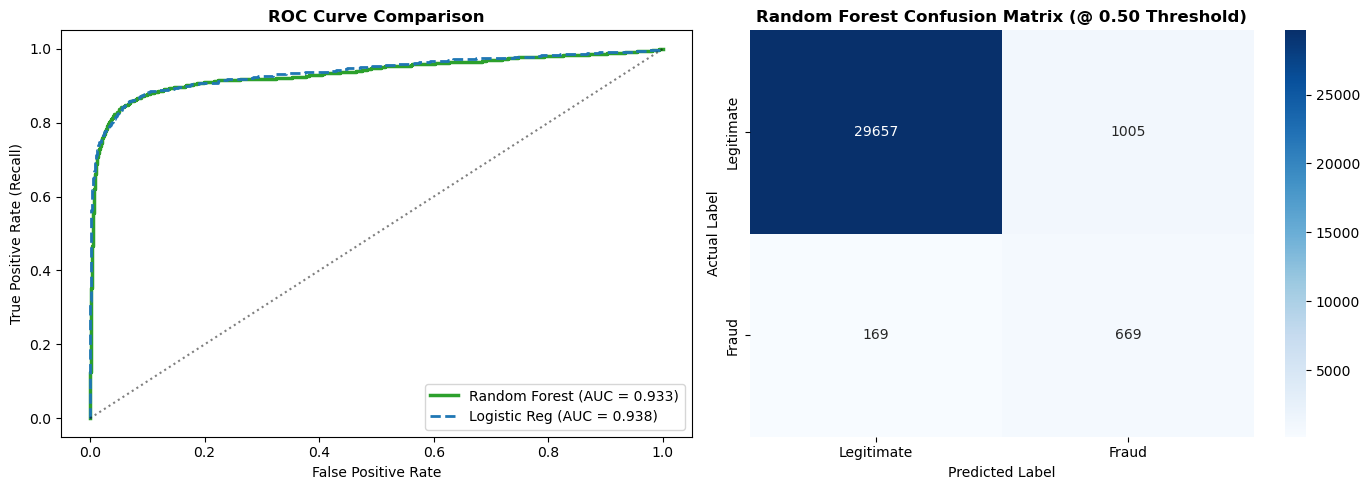

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC Curve
fpr_lr, tpr_lr, _ = roc_curve(y_test, prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, prob_rf)

axes[0].plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {roc_auc_score(y_test, prob_rf):.3f})', color='#2ca02c', lw=2.5)
axes[0].plot(fpr_lr, tpr_lr, label=f'Logistic Reg (AUC = {roc_auc_score(y_test, prob_lr):.3f})', color='#1f77b4', linestyle='--', lw=2)
axes[0].plot([0, 1], [0, 1], 'k:', alpha=0.5)
axes[0].set_title('ROC Curve Comparison', fontsize=12, fontweight='bold')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate (Recall)')
axes[0].legend(loc='lower right')

# Confusion Matrix for Champion Model (Random Forest)
cm_rf = confusion_matrix(y_test, pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['Legitimate', 'Fraud'], yticklabels=['Legitimate', 'Fraud'])
axes[1].set_title('Random Forest Confusion Matrix (@ 0.50 Threshold)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('Actual Label')
plt.tight_layout()
plt.show()

### 6. Set Adjustable Alert Thresholds (70%, 80%, 90% Catch Rate)
In real operations, fraud teams have limited review capacity. Flagging too many payments overwhelms analysts, while flagging too few lets fraud slip through. The alert cutoff score is adjusted here so the business can select whether to catch 70%, 80%, or 90% of all fraud.


In [6]:
precisions, recalls, thresholds = precision_recall_curve(y_test, prob_rf)

def find_operating_threshold(target_recall):
    idx = np.argmin(np.abs(recalls - target_recall))
    thresh = thresholds[min(idx, len(thresholds)-1)]
    pred_at_t = (prob_rf >= thresh).astype(int)
    actual_rec = recall_score(y_test, pred_at_t)
    actual_prec = precision_score(y_test, pred_at_t)
    alert_count = pred_at_t.sum()
    alert_rate = alert_count / len(y_test) * 100
    return thresh, actual_rec*100, actual_prec*100, alert_count, alert_rate

threshold_rows = []
for target in [0.70, 0.80, 0.90]:
    t, rec, prec, alerts, rate = find_operating_threshold(target)
    threshold_rows.append({
        'Operating Policy': f'{int(target*100)}% Target Recall',
        'Probability Threshold': round(float(t), 4),
        'Realized Recall (%)': round(float(rec), 2),
        'Realized Precision (%)': round(float(prec), 2),
        'Flagged Queue Volume': int(alerts),
        'Queue Alert Rate (%)': round(float(rate), 2)
    })

thresh_df = pd.DataFrame(threshold_rows)
print('Tunable Operating Thresholds')
print(thresh_df.to_string(index=False))

Tunable Operating Thresholds
 Operating Policy  Probability Threshold  Realized Recall (%)  Realized Precision (%)  Flagged Queue Volume  Queue Alert Rate (%)
70% Target Recall                 0.7048                70.05                   61.02                   962                  3.05
80% Target Recall                 0.4884                79.95                   39.34                  1703                  5.41
90% Target Recall                 0.1616                89.98                   12.86                  5865                 18.62


### 7. Identify Top Behavioral Fraud Indicators
Looks inside the selected champion Random Forest model to see which behavioral clues contributed the most to its fraud risk predictions.


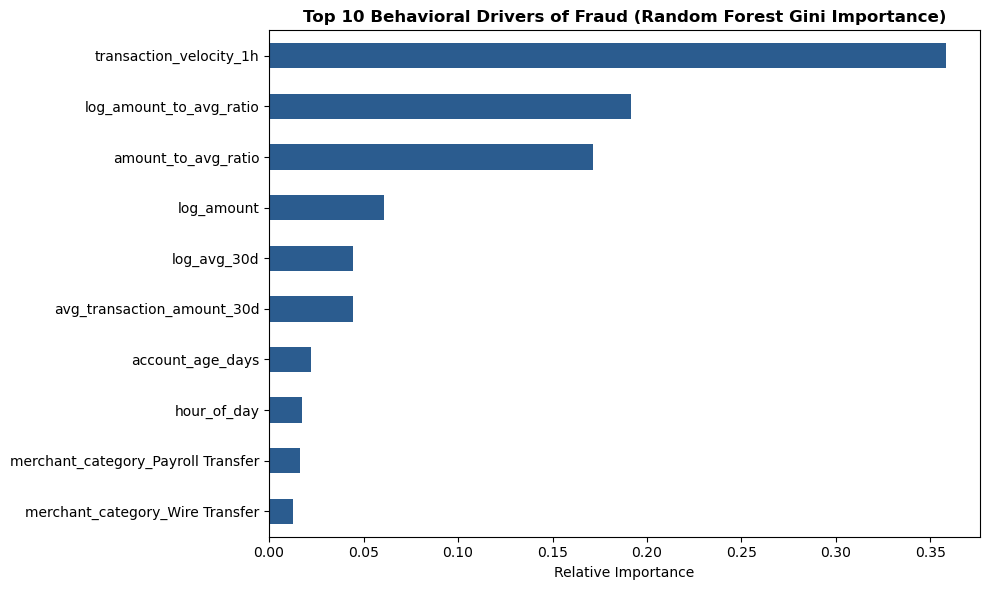

Top 5 most impactful signals:
 - transaction_velocity_1h: 35.83% relative contribution
 - log_amount_to_avg_ratio: 19.16% relative contribution
 - amount_to_avg_ratio: 17.12% relative contribution
 - log_amount: 6.07% relative contribution
 - log_avg_30d: 4.45% relative contribution


In [7]:
importances = pd.Series(rf_model.feature_importances_, index=feature_cols).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
importances.tail(10).plot(kind='barh', color='#2b5c8f')
plt.title('Top 10 Behavioral Drivers of Fraud (Random Forest Gini Importance)', fontsize=12, fontweight='bold')
plt.xlabel('Relative Importance')
plt.tight_layout()
plt.show()

print('Top 5 most impactful signals:')
for feat, imp in importances.tail(5)[::-1].items():
    print(f' - {feat}: {imp*100:.2f}% relative contribution')

### 8. Save Evaluation Results and Test Predictions
Saves data/processed/holdout_predictions.csv and model/evaluation_summary.json so the interactive Streamlit review dashboard can display them.


In [8]:
test_indices = X_test.index
holdout_df = clean_df.loc[test_indices, [
    'transaction_id', 'account_id', 'timestamp', 'amount', 'account_type',
    'kyc_tier', 'channel', 'merchant_category', 'is_fraud'
]].copy()

holdout_df['amount_to_avg_ratio'] = clean_df.loc[test_indices, 'amount_to_avg_ratio'].round(2)
holdout_df['transaction_velocity_1h'] = clean_df.loc[test_indices, 'transaction_velocity_1h']
holdout_df['is_new_device'] = clean_df.loc[test_indices, 'is_new_device']
holdout_df['is_cross_border'] = clean_df.loc[test_indices, 'is_cross_border']
holdout_df['fraud_probability'] = prob_rf.round(4)
holdout_df['baseline_lr_probability'] = prob_lr.round(4)

# Sort descending by risk score to form prioritized queue
holdout_df = holdout_df.sort_values('fraud_probability', ascending=False).reset_index(drop=True)

holdout_path = os.path.join(proc_dir, 'holdout_predictions.csv')
holdout_df.to_csv(holdout_path, index=False)

# Export the selected champion model artifact for production deployment
rf_champ_path = os.path.join(model_dir, 'random_forest_champion.joblib')
joblib.dump(rf_model, rf_champ_path)

# Export evaluation metrics JSON
eval_summary = {
    'test_set_size': int(len(X_test)),
    'test_fraud_count': int(y_test.sum()),
    'benchmark_models': {
        'logistic_regression': {
            'roc_auc': float(roc_auc_score(y_test, prob_lr)),
            'pr_auc': float(average_precision_score(y_test, prob_lr)),
            'precision_default': float(precision_score(y_test, pred_lr)),
            'recall_default': float(recall_score(y_test, pred_lr)),
            'f1_default': float(f1_score(y_test, pred_lr))
        },
        'random_forest_champion': {
            'roc_auc': float(roc_auc_score(y_test, prob_rf)),
            'pr_auc': float(average_precision_score(y_test, prob_rf)),
            'precision_default': float(precision_score(y_test, pred_rf)),
            'recall_default': float(recall_score(y_test, pred_rf)),
            'f1_default': float(f1_score(y_test, pred_rf))
        }
    },
    'tunable_thresholds': threshold_rows
}

summary_json_path = os.path.join(model_dir, 'evaluation_summary.json')
with open(summary_json_path, 'w', encoding='utf-8') as f:
    json.dump(eval_summary, f, indent=2)

print(f'Holdout predictions saved to: {holdout_path} ({len(holdout_df):,} records)')
print(f'Champion model exported to: {rf_champ_path}')
print(f'Evaluation summary JSON exported to: {summary_json_path}')


Holdout predictions saved to: ..\data\processed\holdout_predictions.csv (31,500 records)
Champion model exported to: ..\model\random_forest_champion.joblib
Evaluation summary JSON exported to: ..\model\evaluation_summary.json


Next Step: In 06_production_governance.ipynb, the selected champion model is deployed to work: creating a live scoring function, establishing 3 action steps, and setting up maintenance rules to keep the model updated over time.
